# Information-Free Novelty

This notebook goes through the project with the same scripts that made the figures.
The forager runs are quick. The fitness landscape is loaded from `results/` because it
took hours on the Stanage cluster to compute.

In [1]:
import os
import warnings
import numpy as np
from IPython.display import Image, Video, display

from scripts import render_agent_single_patch
from scripts import render_landscapes, render_mismatch_load
from scripts.compute_ladder import summarise
from scripts.fitness import evaluate_genome_per_world, eval_seeds
from scripts.params import BASE_PARAMS, ANCESTRAL_GENOME

warnings.filterwarnings('ignore')   # for the ODE which gives some warnings about the integration method

OUT = 'results/notebook'   # figures made here go in this folder
os.makedirs(OUT, exist_ok=True)
STACK = 'results/ladder_res40/ladder_stack.npz'

## One forager, one patch

This is the forager tuned to the ancestral world (R̄ = 8.7, κ = 2.98). It starts in the
corner, wanders until it picks up the scent, then goes in and feeds. On the right is
its neuron: V is the membrane potential and β is the opportunity cost.

Change `m` to put it in a more modern world (0 is ancestral, 1 is modern).

saved results/notebook/single_patch.png  (harvested=15.3, n_steps=6179)


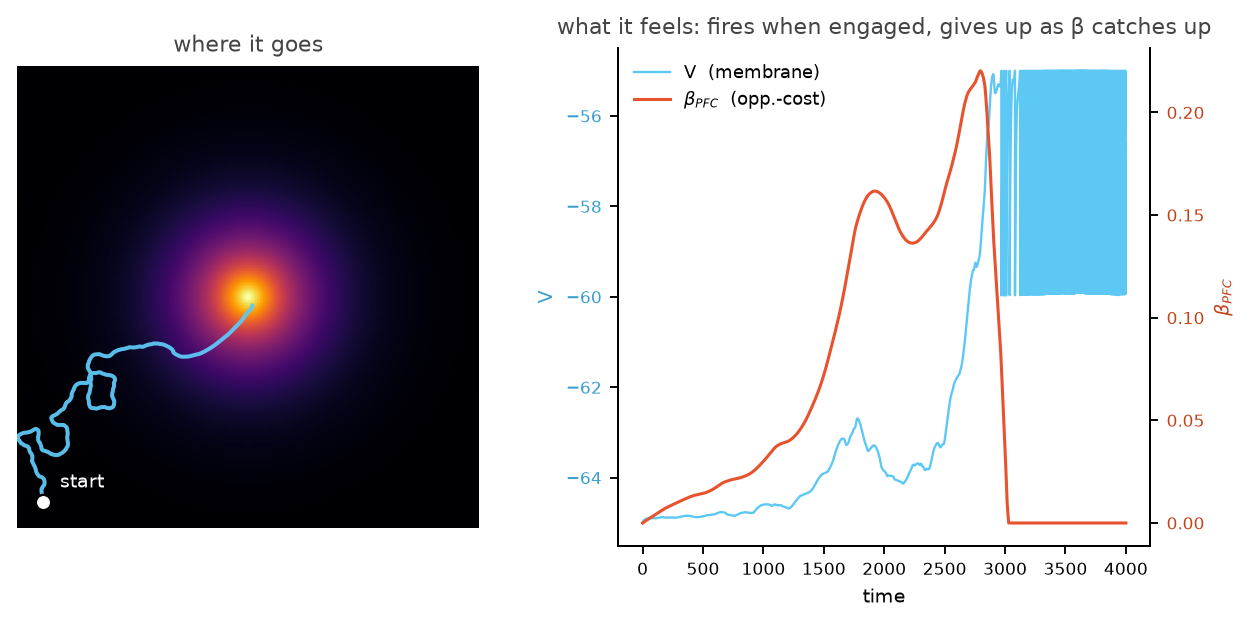

In [2]:
m = 0.10
render_agent_single_patch.render(f'{OUT}/single_patch.png', mismatch_index=m)
display(Image(f'{OUT}/single_patch.png'))

## The forager video

The same forager in a world with three patches. This is a short version so it doesn't
take long to make; `python -m scripts.render_forager_video` makes the full 40 seconds.

In [ ]:
from scripts import render_forager_video   # needs imageio-ffmpeg

m = 0.0
render_forager_video.render(f'{OUT}/forager.mp4', mismatch_index=m, seconds=8, fps=24)
display(Video(f'{OUT}/forager.mp4', embed=True, width=320))

## The fitness landscape

Every square is one forager. R̄ is how rich it expects the world to be and κ is how
much it likes novelty. Each one was scored on 8 worlds of 25,000 time units.

Both traits matter over orders of magnitude, so I used log axes. Set `even = True` to
see it on normal axes, and pick which mismatch levels to show with `levels`
(any of 0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1).

shown rungs: ['0.00', '0.10', '0.30', '0.50', '1.00']  vmin=-0.103 vmax=0.714
saved results/notebook/landscapes.png


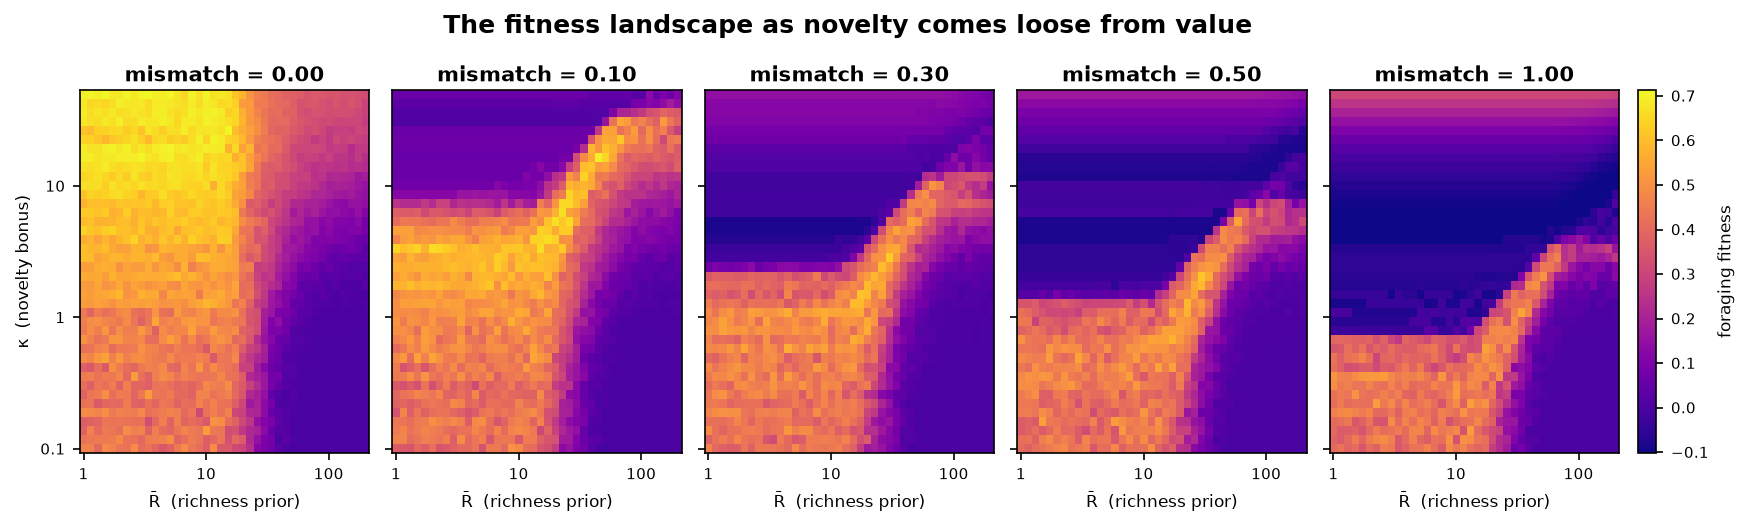

In [4]:
levels = [0, 0.1, 0.3, 0.5, 1]
even = False
render_landscapes.render(STACK, f'{OUT}/landscapes.png', levels, even)
display(Image(f'{OUT}/landscapes.png'))

The best forager at each level, over the whole grid and inside the box (R̄ ≤ 25,
κ ≤ 15), which is what I took to be biologically plausible. A cell's standard error
is about 0.05, so cells closer than that are basically tied.

In [5]:
summarise(STACK)

model=pure-v2  grid 40x40 (log)  box has 24x32 cells
standard error of a cell (between worlds): median 0.051, max 0.118
  mismatch=0.00  best +0.714 at R=1.5 k=50.00  | box best +0.687 at R=1.5 k=13.97
  mismatch=0.05  best +0.709 at R=22.8 k=11.92  | box best +0.709 at R=22.8 k=11.92
  mismatch=0.10  best +0.694 at R=44.9 k=16.39  | box best +0.667 at R=19.9 k=5.37
  mismatch=0.20  best +0.651 at R=34.2 k=4.58  | box best +0.637 at R=8.8 k=2.06
  mismatch=0.30  best +0.627 at R=29.9 k=2.84  | box best +0.608 at R=17.3 k=1.50
  mismatch=0.50  best +0.613 at R=29.9 k=2.06  | box best +0.585 at R=22.8 k=1.28
  mismatch=0.75  best +0.563 at R=15.1 k=0.49  | box best +0.563 at R=15.1 k=0.49
  mismatch=1.00  best +0.547 at R=34.2 k=1.09  | box best +0.536 at R=17.3 k=0.58
ancestral-tuned genome (top 10% of box at mismatch=0.10): ANCESTRAL_GENOME = (8.7, 2.98)


To look up any forager, this finds the nearest cell and prints its score at every
mismatch level.

In [6]:
z = np.load(STACK)


def lookup(R_bar, kappa):
    i = np.abs(np.log(z['R_bar'] / R_bar)).argmin()
    j = np.abs(np.log(z['kappa'] / kappa)).argmin()
    print(f"nearest cell: R̄ = {z['R_bar'][i]:.1f}, κ = {z['kappa'][j]:.2f}")
    for m, f, se in zip(z['rungs'], z['F'][:, i, j], z['F_se'][:, i, j]):
        print(f'  m = {m:.2f}   {f:+.2f} ± {se:.2f}')


lookup(*ANCESTRAL_GENOME)

nearest cell: R̄ = 8.8, κ = 2.84
  m = 0.00   +0.60 ± 0.02
  m = 0.05   +0.57 ± 0.04
  m = 0.10   +0.54 ± 0.05
  m = 0.20   +0.42 ± 0.10
  m = 0.30   -0.02 ± 0.05
  m = 0.50   -0.06 ± 0.05
  m = 0.75   -0.06 ± 0.05
  m = 1.00   -0.05 ± 0.05


## The mismatch load

Red is the ancestral forager, kept the same while the world changes. Green is the best
forager in the box for each world. Both were scored again on 32 new worlds, so green
isn't just the luckiest cell. The gap between them is the mismatch load.

red  : ['+0.556', '+0.267', '+0.078', '+0.027', '+0.025', '+0.023']
green: ['+0.564', '+0.471', '+0.562', '+0.500', '+0.470', '+0.501']
saved results/notebook/mismatch_load.png


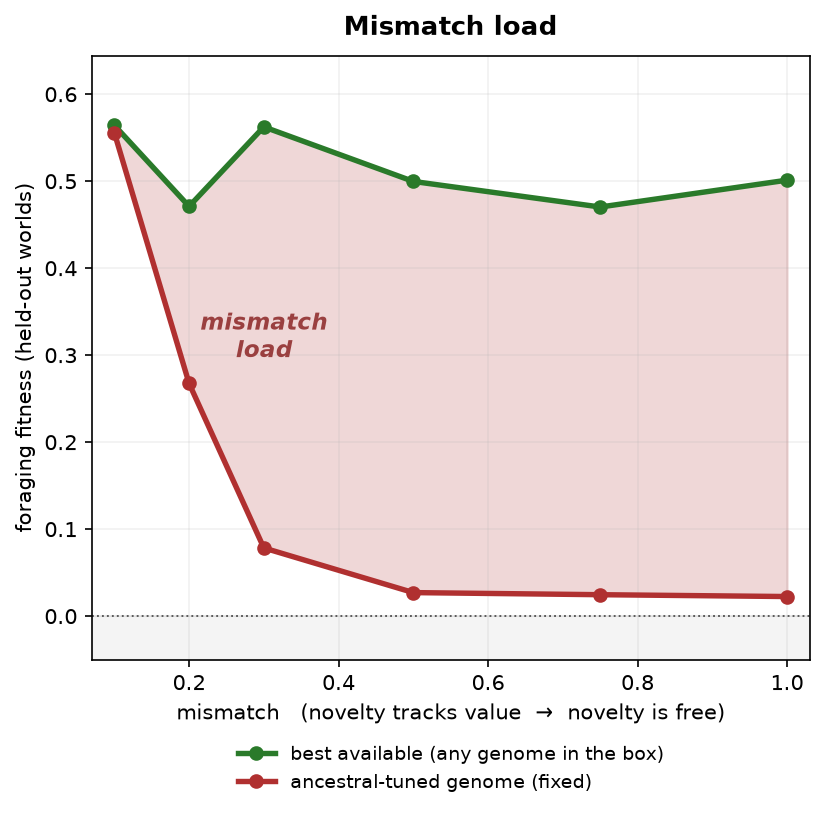

In [7]:
render_mismatch_load.render(f'{OUT}/mismatch_load.png')
display(Image(f'{OUT}/mismatch_load.png', width=450))

## Try your own forager

This runs the real fitness function on one world per mismatch level, 25,000 time units
like the landscape. It takes about a minute per level. One world is noisy, the
landscape used 8.

In [8]:
genome = (8.7, 2.98)   # (R̄, κ), try (17.3, 0.58) which is the best in the box at m = 1

for m in (0.0, 0.3, 1.0):
    args = (np.array(genome), BASE_PARAMS, eval_seeds(1), 25_000, 20_000,
            {'mismatch_index': m, 'space_initial_patches': False})
    print(f'm = {m}:  fitness {evaluate_genome_per_world(args)[0]:+.2f}')

m = 0.0:  fitness +0.58


m = 0.3:  fitness -0.09


m = 1.0:  fitness -0.13
